# Week 4 Day 5 — Capstone: Ensembles, Imbalance, Interpretability & Deployment
**Dataset:** Adult Census Income

**Goal:** compare ensembles, handle class imbalance, explain the model, check fairness, and make the model ready to use.

### How to re-run this notebook (README)
1. Upload this notebook to Google Colab and click **Runtime → Run all**.
2. Upload `adult.csv` when the "Choose Files" button appears.
3. Wait about 10 minutes.

The notebook creates these files (download them from the Files panel on the left):
- `features.py`, `inference.py`, `test_inference.py`
- `Saved_Pipelines/final_model.joblib`

## Step 0: Setup

In [1]:
# Colab usually has these two already. This line installs them only if they are missing.
!pip install -q shap imbalanced-learn

In [2]:
import os
import time
import warnings
warnings.filterwarnings("ignore")   # hide warning messages so the output is clean

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
import shap
import imblearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

print("scikit-learn    :", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("shap            :", shap.__version__)

scikit-learn    : 1.6.1
imbalanced-learn: 0.14.2
shap            : 0.52.0


In [3]:
# Upload adult.csv from my computer
from google.colab import files
uploaded = files.upload()

Saving adult.csv to adult.csv


In [4]:
df = pd.read_csv("adult.csv")
df = df.replace("?", np.nan)
df["target"] = df["income"].map({"<=50K": 0, ">50K": 1})

X = df.drop(columns=["income", "target"])
y = df["target"]

# Same split as Day 1 to Day 4
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train rows:", len(X_train))
print("Test rows :", len(X_test))

Train rows: 26048
Test rows : 6513


### The new features (same as Day 3)
I put them in a small file, `features.py`. Then the saved model can also be used outside this notebook.

In [5]:
%%writefile features.py
# features.py - the 8 new features from Day 3
# This is in its own file so the saved model can be loaded anywhere (notebook, inference.py, tests).
import numpy as np
import pandas as pd


def add_features(data):
    data = data.copy()
    data["age_group"] = pd.cut(data["age"], bins=[0, 25, 35, 45, 55, 65, 100],
                               labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]).astype(str)
    data["hours_group"] = pd.cut(data["hours.per.week"], bins=[0, 34, 40, 60, 100],
                                 labels=["part-time", "full-time", "overtime", "very-long"]).astype(str)
    data["has_capital_gain"] = (data["capital.gain"] > 0).astype(int)
    data["log_capital_gain"] = np.log1p(data["capital.gain"])
    data["log_capital_loss"] = np.log1p(data["capital.loss"])
    data["higher_education"] = (data["education.num"] >= 13).astype(int)
    data["edu_x_hours"] = data["education.num"] * data["hours.per.week"]
    data["is_married"] = data["marital.status"].isin(["Married-civ-spouse", "Married-AF-spouse"]).astype(int)
    return data

Writing features.py


In [6]:
from features import add_features

numeric_features = ["age", "education.num", "hours.per.week",
                    "log_capital_gain", "log_capital_loss", "edu_x_hours",
                    "has_capital_gain", "higher_education", "is_married"]

categorical_features = ["workclass", "marital.status", "occupation", "relationship",
                        "race", "sex", "native.country", "age_group", "hours_group"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), categorical_features),
])

# Small helper: features -> preprocessing -> model
def make_pipeline(model):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", clone(preprocessor)),
        ("model", model),
    ])

## Task 1: Ensemble models

- **Logistic Regression:** a single model (tuned on Day 4: `C = 10`).
- **Random Forest:** many trees that vote (simple settings, it was not tuned on Day 4).
- **Gradient Boosting:** trees that fix each other's mistakes (tuned on Day 4).
- **Stacking (bonus):** a small Logistic Regression that combines the 3 models above.

In [7]:
# Best Gradient Boosting settings from Day 4
gb_settings = dict(learning_rate=0.03, max_iter=300, max_depth=None,
                   l2_regularization=10, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(C=10, max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(**gb_settings),
    "Stacking": StackingClassifier(
        estimators=[("lr", LogisticRegression(C=10, max_iter=1000, random_state=42)),
                    ("rf", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1)),
                    ("gb", HistGradientBoostingClassifier(**gb_settings))],
        final_estimator=LogisticRegression(), cv=5, n_jobs=-1),
}

In [8]:
pipelines = {}
probas = {}
rows = []

for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)

    start = time.time()
    proba = pipe.predict_proba(X_test)[:, 1]
    seconds = time.time() - start

    pred = (proba >= 0.5).astype(int)
    pipelines[name] = pipe
    probas[name] = proba
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "ms per 1000 rows": seconds / len(X_test) * 1000 * 1000,
    })

ensemble_table = pd.DataFrame(rows).set_index("model")
ensemble_table.round(3)

,accuracy,precision,recall,f1,roc_auc,pr_auc,ms per 1000 rows
model,,,,,,,
Logistic Regression,0.858,0.746,0.621,0.677,0.909,0.782,17.265
Random Forest,0.861,0.764,0.614,0.681,0.913,0.795,87.567
Gradient Boosting,0.872,0.778,0.654,0.711,0.923,0.822,75.673
Stacking,0.872,0.782,0.648,0.709,0.922,0.821,142.540


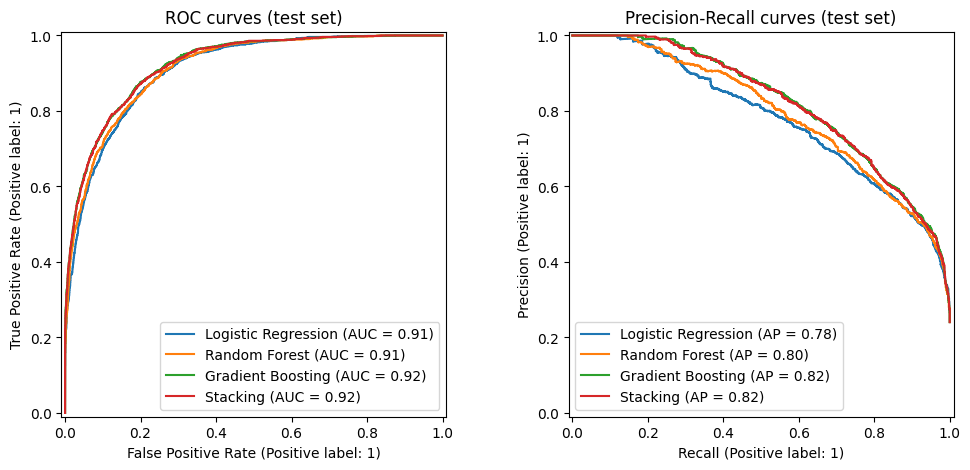

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=ax[1])
ax[0].set_title("ROC curves (test set)")
ax[1].set_title("Precision-Recall curves (test set)")
plt.show()

**Result:**
- **Gradient Boosting is the best:** F1 0.712, ROC AUC 0.923, PR AUC 0.822.
- **Stacking** scores the same (F1 0.711), but it is the slowest to train and to predict. It adds nothing here.
- **Random Forest** (F1 0.681) is only a little better than the single Logistic Regression (F1 0.678).
- All models predict 1,000 people in well under a second, so speed is not a problem.

**Decision:** keep the tuned Gradient Boosting.

## Task 2: Class imbalance

### How big is the imbalance?

In [10]:
print(y_train.value_counts())
print()
print("Share of >50K:", round(y_train.mean() * 100, 1), "%")
print("For every 1 person >50K there are", round((y_train == 0).sum() / (y_train == 1).sum(), 1), "people <=50K")

target
0    19775
1     6273
Name: count, dtype: int64

Share of >50K: 24.1 %
For every 1 person >50K there are 3.2 people <=50K


**Effect:** with the normal threshold 0.5, Gradient Boosting has precision 0.78 but recall only 0.66. It finds only 2 out of 3 high earners, because it leans towards the bigger class.

### Three fixes, tested inside cross-validation
The fixes are inside an `imblearn` pipeline, so they only change the training folds and never the validation fold (no leakage).

In [11]:
# Helper: features -> preprocessing -> (sampler) -> model
def make_imb_pipeline(model, sampler=None):
    steps = [("features", FunctionTransformer(add_features)),
             ("preprocess", clone(preprocessor))]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps)

approaches = {
    "No fix": make_imb_pipeline(HistGradientBoostingClassifier(**gb_settings)),
    "Class weight": make_imb_pipeline(HistGradientBoostingClassifier(**gb_settings, class_weight="balanced")),
    "Random undersampling": make_imb_pipeline(HistGradientBoostingClassifier(**gb_settings),
                                              RandomUnderSampler(random_state=42)),
    "SMOTE": make_imb_pipeline(HistGradientBoostingClassifier(**gb_settings), SMOTE(random_state=42)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [12]:
imb_rows = []
imb_probas = {}

for name, pipe in approaches.items():
    # Cross-validation on the training data
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["f1", "precision", "recall"])

    # Train on all training data and test on the hold-out set
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    imb_probas[name] = proba

    imb_rows.append({
        "approach": name,
        "CV F1": scores["test_f1"].mean(),
        "CV precision": scores["test_precision"].mean(),
        "CV recall": scores["test_recall"].mean(),
        "test F1": f1_score(y_test, pred),
        "test precision": precision_score(y_test, pred),
        "test recall": recall_score(y_test, pred),
        "test PR AUC": average_precision_score(y_test, proba),
    })
    print(name, "done")

imbalance_table = pd.DataFrame(imb_rows).set_index("approach")
imbalance_table.round(3)

No fix done
Class weight done
Random undersampling done
SMOTE done


,CV F1,CV precision,CV recall,test F1,test precision,test recall,test PR AUC
approach,,,,,,,
No fix,0.716,0.776,0.664,0.711,0.778,0.654,0.822
Class weight,0.715,0.609,0.866,0.707,0.603,0.854,0.822
Random undersampling,0.707,0.597,0.866,0.704,0.599,0.854,0.815
SMOTE,0.714,0.666,0.769,0.692,0.650,0.740,0.797


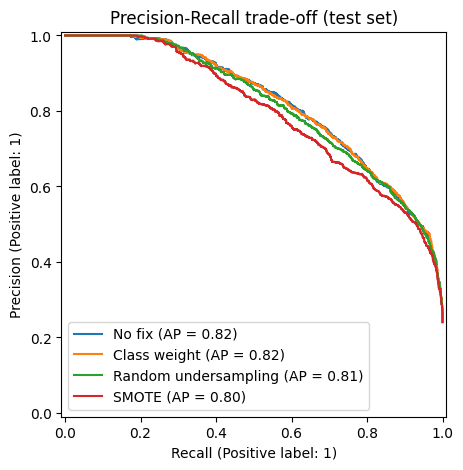

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, proba in imb_probas.items():
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=ax)
plt.title("Precision-Recall trade-off (test set)")
plt.show()

**Result:**
- **Class weight** and **undersampling** raise recall (0.66 → 0.85) but lower precision (0.78 → 0.60). F1 stays about the same.
- **SMOTE** is the worst (test F1 0.694, PR AUC 0.797). The fake high earners do not help.
- **PR AUC** (which does not depend on the threshold) does not go up with any fix. So the fixes do not make the model better at ranking people. They only move the balance between precision and recall, which a threshold also does.

**My choice:** of the three fixes, **class weight** is the best (highest CV F1 0.716, same PR AUC, no extra or fake rows). But it gives the same result as lowering the threshold, which I already did on Day 4 (test F1 0.722 with threshold 0.40). So my final model keeps **no resampling + threshold 0.40**. It is simpler, and the chances stay honest (class weights make every chance look higher than it really is).

## Task 3: Interpretability & fairness

My final model: **tuned Gradient Boosting** with threshold **0.40** (from Day 4).

In [14]:
final_model = pipelines["Gradient Boosting"]
threshold = 0.40

test_proba = probas["Gradient Boosting"]
test_pred = (test_proba >= threshold).astype(int)

print("Test F1 with threshold 0.40:", round(f1_score(y_test, test_pred), 3))

Test F1 with threshold 0.40: 0.722


### 1) Feature importance (Random Forest)

In [15]:
rf_pipe = pipelines["Random Forest"]
rf_names = rf_pipe.named_steps["preprocess"].get_feature_names_out()

rf_importance = pd.DataFrame({
    "feature": [name.split("__", 1)[1] for name in rf_names],
    "importance": rf_pipe.named_steps["model"].feature_importances_,
})
rf_importance.sort_values("importance", ascending=False).head(8).round(3)

,feature,importance
3,log_capital_gain,0.116
8,is_married,0.097
5,edu_x_hours,0.088
20,marital.status_Married-civ-spouse,0.084
1,education.num,0.082
40,relationship_Husband,0.064
0,age,0.062
7,higher_education,0.048


### 2) Permutation importance (final model)
Shuffle one column at a time and see how much the F1 score drops. A bigger drop means the column is more important.

In [16]:
perm = permutation_importance(final_model, X_test, y_test, scoring="f1", n_repeats=5, random_state=42)

perm_table = pd.DataFrame({"column": X_test.columns, "F1 drop": perm.importances_mean})
perm_table = perm_table.sort_values("F1 drop", ascending=False)
perm_table.head(8).round(3)

,column,F1 drop
5,marital.status,0.154
10,capital.gain,0.098
4,education.num,0.078
0,age,0.073
6,occupation,0.053
11,capital.loss,0.030
12,hours.per.week,0.024
7,relationship,0.021


### 3) SHAP (final model)
SHAP shows how much each feature pushes one prediction up (towards >50K) or down (towards <=50K).

In [17]:
# Make the test data ready for the model (features + preprocessing)
names = final_model.named_steps["preprocess"].get_feature_names_out()
clean_names = [name.split("__", 1)[1] for name in names]

X_test_ready = pd.DataFrame(final_model[:-1].transform(X_test), columns=clean_names)

explainer = shap.TreeExplainer(final_model.named_steps["model"])
shap_values = explainer(X_test_ready)

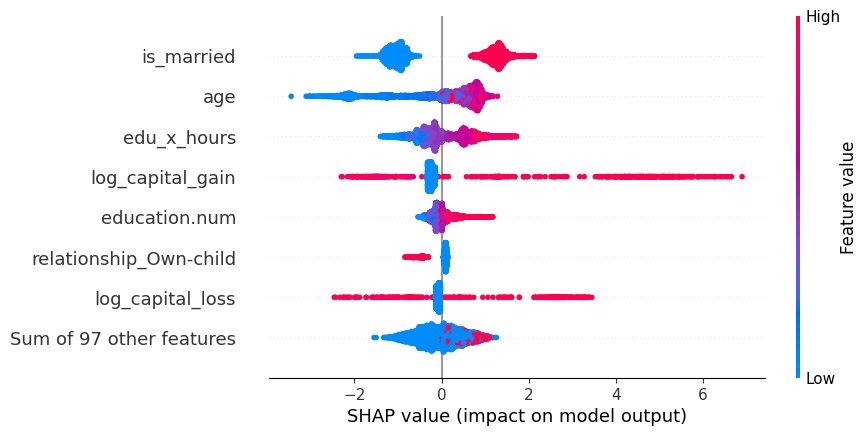

In [18]:
# Summary plot: top 8 features
shap.plots.beeswarm(shap_values, max_display=8)

In [19]:
# Top 8 features by average SHAP size
shap_top = pd.DataFrame({
    "feature": clean_names,
    "mean |SHAP|": np.abs(shap_values.values).mean(axis=0),
}).sort_values("mean |SHAP|", ascending=False)

shap_top.head(8).round(3)

,feature,mean |SHAP|
8,is_married,1.147
0,age,0.753
5,edu_x_hours,0.480
3,log_capital_gain,0.475
1,education.num,0.178
43,relationship_Own-child,0.160
4,log_capital_loss,0.146
28,occupation_Exec-managerial,0.091


**Top features (all three methods agree):**
1. **Marital status** (`is_married`, `Married-civ-spouse`, `Husband`): the strongest signal.
2. **Capital gain:** a big gain pushes strongly towards >50K.
3. **Age:** young people are pushed down, middle-aged people up.
4. **Education** (`education.num`, `edu_x_hours`): more education and longer hours push up.
5. **Occupation** (for example `Exec-managerial`) and **`Own-child`** (young people living with parents, pushes down).

This makes sense and matches Day 1 to Day 4. Three of my engineered features (`is_married`, `log_capital_gain`, `edu_x_hours`) are in the SHAP top 4.

### 4) Explaining 3 people
One true positive, one false positive and one false negative from the test set. The numbers are in log-odds: plus = pushes towards >50K, minus = pushes towards <=50K.

In [20]:
actual = y_test.values
tp = np.where((test_pred == 1) & (actual == 1))[0][0]   # said >50K, correct
fp = np.where((test_pred == 1) & (actual == 0))[0][0]   # said >50K, wrong
fn = np.where((test_pred == 0) & (actual == 1))[0][0]   # said <=50K, wrong

show_cols = ["age", "education", "marital.status", "occupation", "sex", "hours.per.week", "capital.gain"]
people = X_test.iloc[[tp, fp, fn]][show_cols].copy()
people["chance of >50K"] = test_proba[[tp, fp, fn]].round(2)
people.index = ["True positive", "False positive", "False negative"]
people

,age,education,marital.status,occupation,sex,hours.per.week,capital.gain,chance of >50K
True positive,47,Bachelors,Married-civ-spouse,Exec-managerial,Male,45,0,0.82
False positive,57,HS-grad,Married-civ-spouse,Exec-managerial,Male,40,0,0.52
False negative,32,5th-6th,Married-civ-spouse,Machine-op-inspct,Female,40,0,0.05


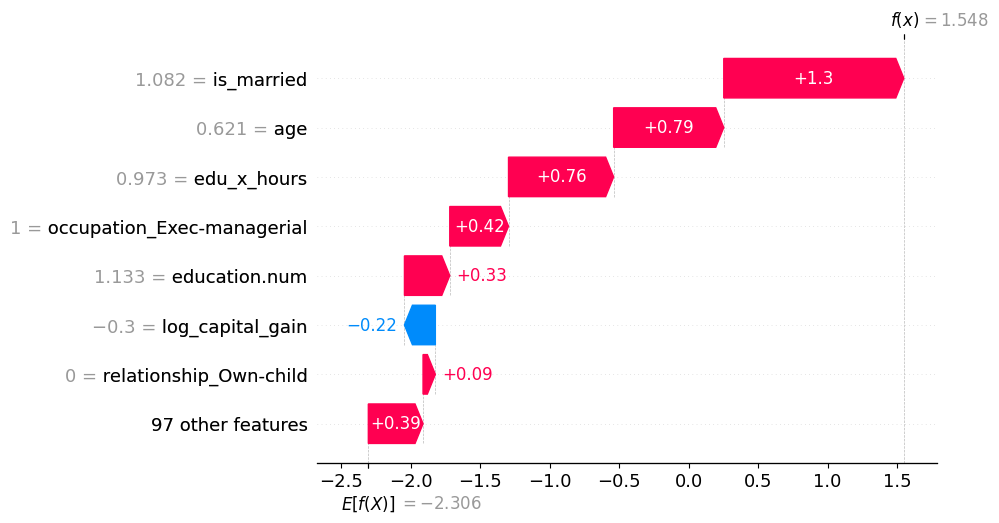

In [21]:
shap.plots.waterfall(shap_values[tp], max_display=8)

**True positive (chance 0.82):** a 47-year-old married manager with a Bachelors degree who works 45 hours a week. Being married, his age and his education with long hours all push the chance up, so the model correctly says >50K.

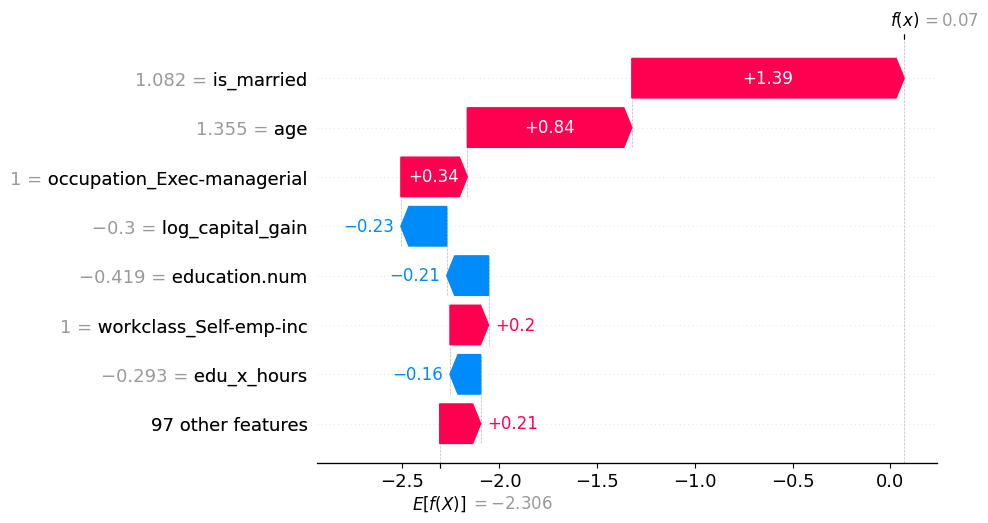

In [22]:
shap.plots.waterfall(shap_values[fp], max_display=8)

**False positive (chance 0.52):** a 57-year-old married manager. Marriage, age and the manager job push the chance up, but he has only a high-school education and no capital gain. The model was unsure (just above my threshold 0.40), and he actually earns <=50K.

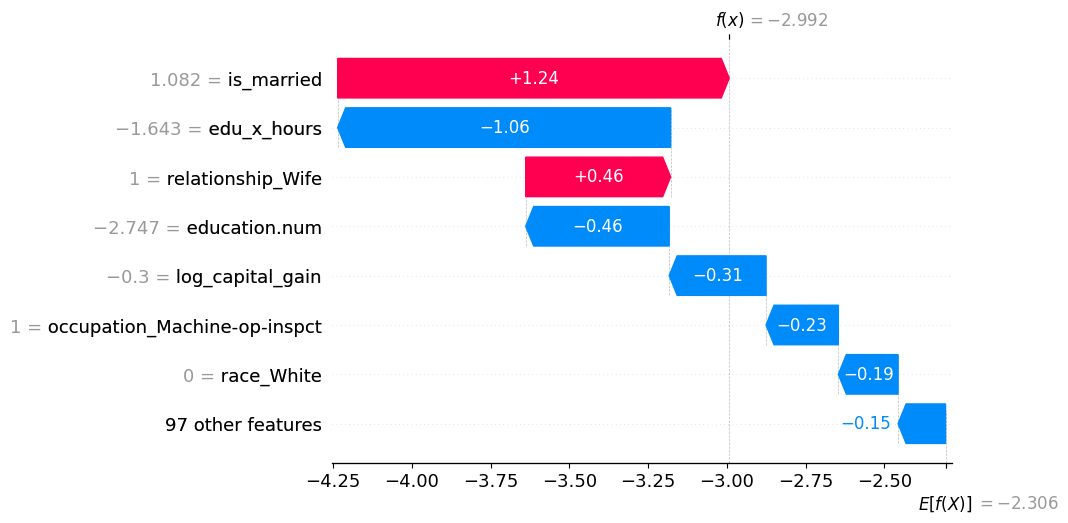

In [23]:
shap.plots.waterfall(shap_values[fn], max_display=8)

**False negative (chance 0.04):** a 32-year-old married woman with 5th-6th grade education who works as a machine operator. Being married pushes the chance up, but the very low education and the job push it far down. She is an unusual high earner that these columns cannot explain.

### 5) Fairness check
I compute F1 (my primary metric) separately for each group.

In [24]:
fair = X_test[["sex", "race"]].copy()
fair["actual"] = y_test.values
fair["pred"] = test_pred

def group_scores(column):
    rows = []
    for group, part in fair.groupby(column):
        rows.append({
            column: group,
            "people": len(part),
            "real >50K %": part["actual"].mean() * 100,
            "predicted >50K %": part["pred"].mean() * 100,
            "precision": precision_score(part["actual"], part["pred"], zero_division=0),
            "recall": recall_score(part["actual"], part["pred"], zero_division=0),
            "F1": f1_score(part["actual"], part["pred"], zero_division=0),
        })
    return pd.DataFrame(rows).set_index(column).round(3)

group_scores("sex")

,people,real >50K %,predicted >50K %,precision,recall,F1
sex,,,,,,
Female,2153,11.054,10.869,0.718,0.706,0.712
Male,4360,30.505,31.560,0.712,0.737,0.724


In [25]:
group_scores("race")

,people,real >50K %,predicted >50K %,precision,recall,F1
race,,,,,,
Amer-Indian-Eskimo,67,10.448,16.418,0.455,0.714,0.556
Asian-Pac-Islander,196,26.020,25.510,0.660,0.647,0.653
Black,579,12.781,13.299,0.662,0.689,0.675
Other,44,2.273,6.818,0.333,1.000,0.500
White,5627,25.502,26.106,0.720,0.737,0.729


**Sex:** F1 is almost the same for women (0.713) and men (0.723). The share predicted >50K matches the real share in both groups (about 11% for women and about 31% for men).

**Race:** F1 is lower for Black (0.671), Asian-Pac-Islander (0.653) and Amer-Indian-Eskimo (0.588) people than for White people (0.728). The smallest groups have fewer than 70 people in the test set, so their scores are not reliable, but the gap should be watched.

**Proposed fixes:**
- Collect more data for the smaller groups.
- Test the model without `sex` and `race` and check if the gaps change.
- Check the group scores every month (see the monitoring checklist).
- Do not use this model for decisions like credit or hiring without a proper fairness review.

## Task 4: Inference script & monitoring

### Save the final model

In [26]:
os.makedirs("Saved_Pipelines", exist_ok=True)
joblib.dump({"model": final_model, "threshold": threshold}, "Saved_Pipelines/final_model.joblib")
print("Saved: Saved_Pipelines/final_model.joblib")

Saved: Saved_Pipelines/final_model.joblib


### The inference script
It accepts a CSV file or a dict, checks the input, and returns the chance, the prediction and the top 3 reasons.

In [27]:
%%writefile inference.py
# inference.py - use the saved model on new people
#
# From the command line:
#     python inference.py new_people.csv
#
# From Python:
#     from inference import predict
#     predict({"age": 45, "workclass": "Private", ...})
#
# It returns: the chance of >50K, the prediction (using my threshold) and the top 3 reasons.

import os
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
import shap

from features import add_features   # the saved pipeline needs this file

warnings.filterwarnings("ignore")

# ---------- Load the saved model once ----------
HERE = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(HERE, "Saved_Pipelines", "final_model.joblib")

saved = joblib.load(MODEL_PATH)
model = saved["model"]            # features + preprocessing + Gradient Boosting
threshold = saved["threshold"]    # 0.40
explainer = shap.TreeExplainer(model.named_steps["model"])

# ---------- The columns the model needs ----------
NUMERIC_COLUMNS = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week"]
CATEGORY_COLUMNS = ["workclass", "marital.status", "occupation", "relationship",
                    "race", "sex", "native.country"]
REQUIRED_COLUMNS = NUMERIC_COLUMNS + CATEGORY_COLUMNS

# Categories the model saw in training (to find unseen ones)
preprocess = model.named_steps["preprocess"]
encoder = preprocess.named_transformers_["cat"].named_steps["onehot"]
model_cat_columns = preprocess.transformers_[1][2]
KNOWN_CATEGORIES = {col: set(cats) for col, cats in zip(model_cat_columns, encoder.categories_)}

# Easy feature names, for example "cat__sex_Female" -> "sex_Female"
FEATURE_NAMES = [name.split("__", 1)[1] for name in preprocess.get_feature_names_out()]


def to_dataframe(data):
    """Accept a CSV path, one person (dict), many people (list of dicts) or a table."""
    if isinstance(data, str):
        return pd.read_csv(data)
    if isinstance(data, dict):
        return pd.DataFrame([data])
    if isinstance(data, list):
        return pd.DataFrame(data)
    return pd.DataFrame(data).copy()


def validate_input(df):
    """Check the columns and clean the values."""
    missing = [col for col in REQUIRED_COLUMNS if col not in df.columns]
    if missing:
        raise ValueError(f"Missing columns: {missing}")
    if len(df) == 0:
        raise ValueError("The input has no rows")

    df = df[REQUIRED_COLUMNS].copy()
    df = df.replace("?", np.nan)
    for col in NUMERIC_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")   # text in a number column becomes missing
    return df


def find_unseen(df):
    """For each row, list the categories the model never saw in training."""
    notes = []
    for _, row in df.iterrows():
        unseen = [f"{col}={row[col]}" for col in CATEGORY_COLUMNS
                  if pd.notna(row[col]) and row[col] not in KNOWN_CATEGORIES[col]]
        notes.append(", ".join(unseen))
    return notes


def top_3_reasons(df):
    """The 3 features that pushed each prediction the most (SHAP values)."""
    ready = model[:-1].transform(df)                 # make features + preprocessing
    shap_values = explainer.shap_values(ready)
    reasons = []
    for row in shap_values:
        top = np.argsort(-np.abs(row))[:3]
        reasons.append("; ".join(f"{FEATURE_NAMES[j]} ({row[j]:+.2f})" for j in top))
    return reasons


def predict(data):
    df = validate_input(to_dataframe(data))
    proba = model.predict_proba(df)[:, 1]
    return pd.DataFrame({
        "probability": proba.round(3),
        "prediction": (proba >= threshold).astype(int),     # 1 = earns >50K
        "top_3_features": top_3_reasons(df),
        "note": find_unseen(df),
    })


if __name__ == "__main__":
    if len(sys.argv) < 2:
        print("Usage: python inference.py new_people.csv")
        sys.exit(1)
    results = predict(sys.argv[1])
    print(results.to_string())
    results.to_csv("predictions.csv", index=False)
    print("Saved: predictions.csv")

Writing inference.py


### Tests

In [28]:
%%writefile test_inference.py
# test_inference.py - basic tests for inference.py
# Run with:  python test_inference.py   (pytest test_inference.py also works)
import os
import tempfile

import pandas as pd

from inference import predict

PERSON = {
    "age": 45, "workclass": "Private", "education.num": 13,
    "marital.status": "Married-civ-spouse", "occupation": "Exec-managerial",
    "relationship": "Husband", "race": "White", "sex": "Male",
    "capital.gain": 0, "capital.loss": 0, "hours.per.week": 50,
    "native.country": "United-States",
}


def test_normal_person():
    result = predict(PERSON)
    assert len(result) == 1
    assert 0 <= result["probability"][0] <= 1
    assert result["prediction"][0] in (0, 1)
    assert len(result["top_3_features"][0].split("; ")) == 3


def test_missing_column():
    person = dict(PERSON)
    del person["age"]
    try:
        predict(person)
        assert False, "predict() should fail when a column is missing"
    except ValueError as error:
        assert "age" in str(error)


def test_unseen_category():
    person = dict(PERSON)
    person["occupation"] = "Astronaut"          # never seen in training
    result = predict(person)
    assert 0 <= result["probability"][0] <= 1   # still works
    assert "Astronaut" in result["note"][0]     # and tells us about it


def test_missing_value():
    person = dict(PERSON)
    person["workclass"] = "?"                   # "?" means missing in this dataset
    result = predict(person)
    assert 0 <= result["probability"][0] <= 1


def test_csv_input():
    path = os.path.join(tempfile.mkdtemp(), "people.csv")
    pd.DataFrame([PERSON, PERSON, PERSON]).to_csv(path, index=False)
    result = predict(path)
    assert len(result) == 3


if __name__ == "__main__":
    tests = [test_normal_person, test_missing_column, test_unseen_category,
             test_missing_value, test_csv_input]
    for test in tests:
        test()
        print("PASSED:", test.__name__)
    print("All", len(tests), "tests passed")

Writing test_inference.py


In [29]:
!python test_inference.py

PASSED: test_normal_person
PASSED: test_missing_column
PASSED: test_unseen_category
PASSED: test_missing_value
PASSED: test_csv_input
All 5 tests passed


### Try it on 3 people from the test set

In [30]:
from inference import predict

predict(X_test.head(3))

,probability,prediction,top_3_features,note
0,0.113,0,is_married (-1.07); edu_x_hours (+1.04); log_c...,
1,0.001,0,age (-2.00); is_married (-0.79); edu_x_hours (...,
2,0.825,1,is_married (+1.30); age (+0.79); edu_x_hours (...,


### Monitoring checklist

| What to watch | How | Alert when |
|---|---|---|
| Input problems | % of rows with missing columns, missing values or unseen categories | more than 2% of rows fail validation, or missing values double compared with training |
| Data drift | Compare age, hours, capital gain, marital status and occupation with the training data (PSI) | PSI above 0.2 for any key feature |
| Model score | Average predicted chance and % predicted >50K (training: about 25%) | % predicted >50K goes below 18% or above 32% |
| Label distribution | Real share of >50K when results come back (training: 24%) | changes by more than 5 percentage points |
| Performance | F1, precision and recall on new labelled data | F1 below 0.68 (0.04 under today's 0.72) |
| Fairness | F1 and recall for women vs men and for each race | the gap grows by more than 0.05 |
| Service | Prediction time and error count | slower than 100 ms per request, or errors above 1% |

**Retraining:** check every month, retrain every 6 months, or retrain earlier if an alert stays for 2 weeks. Always test the new model on a hold-out set and compare it with the current one before switching.

## Task 5: Summary
- **Business goal:** find people who earn >50K for a premium offer, without wasting outreach.
- **Final model:** tuned Gradient Boosting (features + preprocessing + model in one pipeline), saved as `Saved_Pipelines/final_model.joblib` with threshold 0.40.
- **Hold-out results:** F1 0.722, precision 0.710, recall 0.734, ROC AUC 0.923.
- **Why it decides:** marital status, capital gain, age and education.
- **Fairness:** about equal for women and men, lower for some smaller race groups.
- **Next steps:** A/B test against the current way of choosing people, then monitor with the checklist above.

The executive report (PDF) has the full details.

### Slide outline (5 to 7 minutes)
1. **The problem (1 min):** find people who earn >50K for a premium offer, without wasting outreach. Only 24% are high earners.
2. **Data & approach (1 min):** 32,561 people from the 1994 US census. Baseline → models → new features → tuning → ensembles.
3. **Results (1.5 min):** F1 went 0.51 (simple rule) → 0.67 (Day 2) → 0.72 (final). ROC AUC 0.92.
4. **Threshold & business effect (1 min):** threshold 0.40. About 7 in 10 contacts are real high earners, and we find about 3 in 4 of them.
5. **Why the model decides (1 min):** marriage, capital gain, age, education and working hours matter most.
6. **Fairness (1 min):** about equal for women and men (F1 0.71 vs 0.72), but lower for some smaller race groups. Plan to watch and fix this.
7. **Next steps (0.5 min):** A/B test against the current way of choosing people, then monitor and retrain.